# Convergence For Policy Evaluation

Iterative policy evaluation and many other policy iteration methods converge because of the 
**$\gamma$-contracting property of the Bellman update operator** in finite MDPs.

This property does not apply if $\gamma = 1$, but convergence is sill guaranteed if **episodes always terminate** (i.e., reach an absorbing state with al future rewards being 0). 


## Installation and Setup

In [1]:
# uncomment if needed
#%pip install "gym-classics2 @ git+https://github.com/mhahsler/gym-classics2.git"

In [2]:
import numpy as np
np.set_printoptions(precision=2)

In [3]:
import gymnasium as gym
import gym_classics2
gym_classics2.register('gymnasium')

## Define a Non-terminating Maze

We define here the L-maze, but without a terminating goal state. Getting to the goal state just sends the agent back to the start state.
We use a step cost of 1.

In [21]:
from gym_classics2.envs.abstract.gridworld import Gridworld

class LMazeGridworld_non_terminating(Gridworld):
    layout = """
|          |
|        G |
|          |
| XXXXXX   |
|      X   |
|      X   |
|      X   |
|  S   X   |
|          |
|          |
"""

    def __init__(self, tabular = True):
        super().__init__(self.layout, goal_reward=0.0, step_reward=-1.0, tabular=tabular)

    def _next_state(self, state, action):
        if state in self._goals:
            next_state = self.start_states[0]  # Note: Reset to start state if in goal state
        else:
            next_state = self._move(state, action)
        
        if self._is_blocked(next_state):
            next_state = state
        
        # clamp checks if the coordinate is out of bounds. 1.0 is the probability.
        return self._clamp(next_state), 1.0

    def _reward(self, state, action, next_state):      
        if next_state in self._goals: 
            return self._goal_reward  
        
        return self._step_reward

    def _done(self, state, action, next_state):
        return False  # The episode never ends, even if the goal is reached

gym.register('LMaze_non_terminating-v0', entry_point=LMazeGridworld_non_terminating)

/home/mhahsler/miniconda3/envs/reinforcement-learning/lib/python3.12/site-packages/gymnasium/envs/registration.py:637: UserWarning: WARN: Overriding environment LMaze_non_terminating-v0 already in registry.
  logger.warn(f"Overriding environment {new_spec.id} already in registry.")


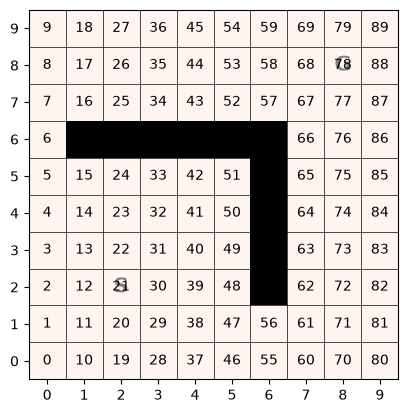

In [22]:
gym_env = gym.make('LMaze_non_terminating-v0', tabular = True)
env = gym_env.unwrapped
env.image()

## Define a Policy

We need to first define a policy we want to evaluate.
Here we find the optimal policy and value function using value iteration with $\gamma = .9$

Value Iteration: 62it [00:00, 297.75it/s]


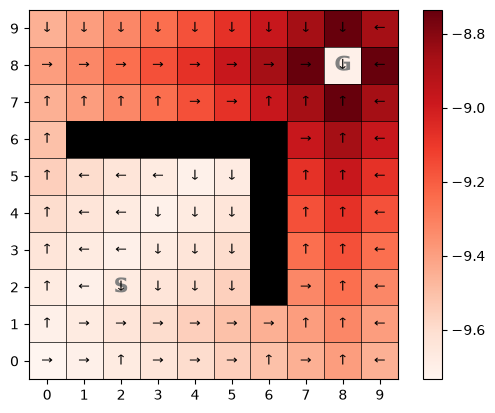

In [23]:
from gym_classics2.algorithms.dynamic_programming import value_iteration, policy_evaluation
from gym_classics2.algorithms.policy import greedy_policy

V_star = value_iteration(env, discount=.9)
pol_star = greedy_policy(V_star, env)
env.image(V_star, policy = pol_star)

## Policy Evaluation with $\gamma < 1$

Evaluation always converges for $\gamma < 1$

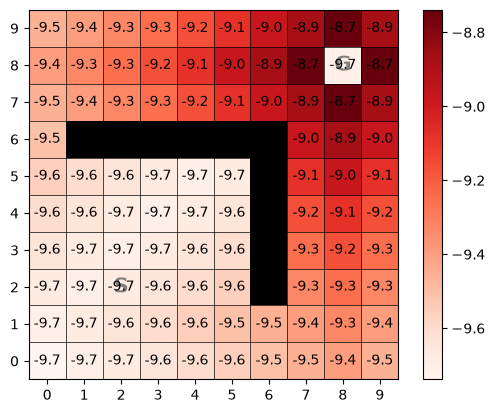

-9.46  -9.40  -9.33  -9.25  -9.17  -9.08  -8.98  -8.86  -8.74  -8.87  
-9.40  -9.33  -9.25  -9.17  -9.08  -8.98  -8.86  -8.74  -9.71  -8.74  
-9.46  -9.40  -9.33  -9.25  -9.17  -9.08  -8.98  -8.86  -8.74  -8.86  
-9.51                                            -8.98  -8.86  -8.98  
-9.56  -9.60  -9.64  -9.68  -9.71  -9.68         -9.08  -8.98  -9.08  
-9.60  -9.64  -9.68  -9.71  -9.68  -9.64         -9.17  -9.08  -9.17  
-9.64  -9.68  -9.71  -9.68  -9.64  -9.60         -9.25  -9.17  -9.25  
-9.68  -9.71  -9.68  -9.64  -9.60  -9.56         -9.33  -9.25  -9.33  
-9.71  -9.68  -9.64  -9.60  -9.56  -9.51  -9.46  -9.40  -9.33  -9.40  
-9.74  -9.71  -9.68  -9.64  -9.60  -9.56  -9.51  -9.46  -9.40  -9.46  


In [25]:
V = policy_evaluation(env, discount=.9, policy=pol_star)
env.image(V, labels = [np.round(v, 1) for v in V])
env.print(V)

## Policy Evaluation with $\gamma = 1$

There is no convergence guarantee.

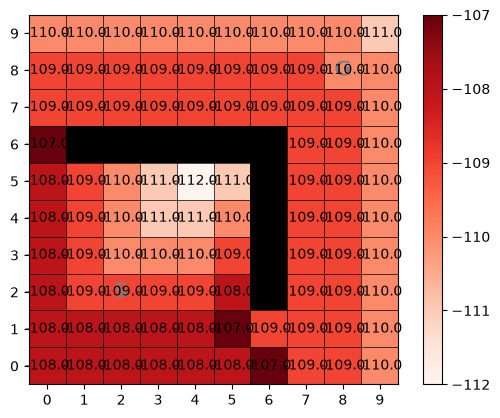

In [26]:
V = policy_evaluation(env, discount=1, policy=pol_star, max_backups=100)
env.image(V, labels = True)

In [27]:
env.print(V)

-110.00  -110.00  -110.00  -110.00  -110.00  -110.00  -110.00  -110.00  -110.00  -111.00  
-109.00  -109.00  -109.00  -109.00  -109.00  -109.00  -109.00  -109.00  -110.00  -110.00  
-109.00  -109.00  -109.00  -109.00  -109.00  -109.00  -109.00  -109.00  -109.00  -110.00  
-107.00                                                        -109.00  -109.00  -110.00  
-108.00  -109.00  -110.00  -111.00  -112.00  -111.00           -109.00  -109.00  -110.00  
-108.00  -109.00  -110.00  -111.00  -111.00  -110.00           -109.00  -109.00  -110.00  
-108.00  -109.00  -110.00  -110.00  -110.00  -109.00           -109.00  -109.00  -110.00  
-108.00  -109.00  -109.00  -109.00  -109.00  -108.00           -109.00  -109.00  -110.00  
-108.00  -108.00  -108.00  -108.00  -108.00  -107.00  -109.00  -109.00  -109.00  -110.00  
-108.00  -108.00  -108.00  -108.00  -108.00  -108.00  -107.00  -109.00  -109.00  -110.00  


The algorithm only stops because of the `max_backups` parameter, that stops the evaluation after the set number of
sweeps over the states. See how the value function increases with stopping after more backups. The evaluation does not converge! 

In [28]:
V = policy_evaluation(env, discount=1, policy=pol_star, max_backups=1000)
env.print(V)

-1079.00  -1079.00  -1079.00  -1079.00  -1079.00  -1079.00  -1079.00  -1079.00  -1078.00  -1079.00  
-1078.00  -1078.00  -1078.00  -1078.00  -1078.00  -1078.00  -1078.00  -1078.00  -1078.00  -1078.00  
-1078.00  -1078.00  -1078.00  -1078.00  -1078.00  -1078.00  -1078.00  -1078.00  -1078.00  -1079.00  
-1078.00                                                              -1078.00  -1078.00  -1079.00  
-1078.00  -1079.00  -1080.00  -1081.00  -1082.00  -1082.00            -1078.00  -1078.00  -1079.00  
-1078.00  -1079.00  -1080.00  -1081.00  -1081.00  -1081.00            -1078.00  -1078.00  -1079.00  
-1076.00  -1077.00  -1078.00  -1080.00  -1080.00  -1080.00            -1078.00  -1078.00  -1079.00  
-1077.00  -1078.00  -1077.00  -1079.00  -1079.00  -1079.00            -1078.00  -1078.00  -1079.00  
-1077.00  -1077.00  -1076.00  -1078.00  -1078.00  -1078.00  -1078.00  -1078.00  -1078.00  -1079.00  
-1077.00  -1077.00  -1077.00  -1076.00  -1078.00  -1078.00  -1078.00  -1078.00  -1078.00  -

## Policy Evaluation with $\gamma = 1$ where the Policy Reaches a Terminating State 

Convergence is also guaranteed if the
policy reaches a terminating state (an absorbing state where the episode ends).

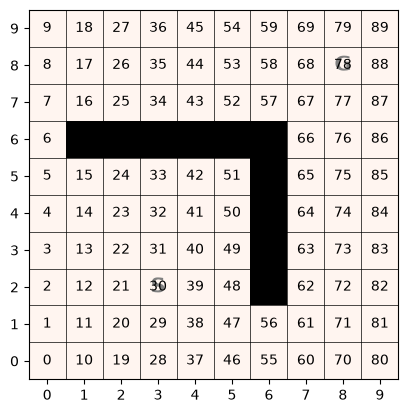

In [29]:
gym_env = gym.make('LMaze-v0', goal_reward = 0.0, step_reward = -1.0, tabular = True)
env = gym_env.unwrapped
env.image()

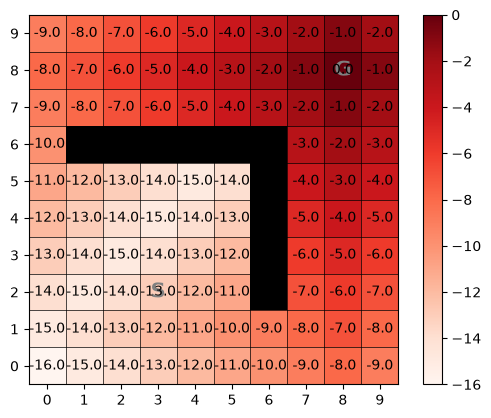

In [30]:
V = policy_evaluation(env, discount=1, policy=pol_star)
env.image(V, labels = True)

We see that the value function for this undiscounted problem shows exactly the number of steps it takes the optimal policy to get to the goal. 

## Policy Evaluation with $\gamma = 1$ where the Policy Does not reaches a Terminating State 

This does not converge.

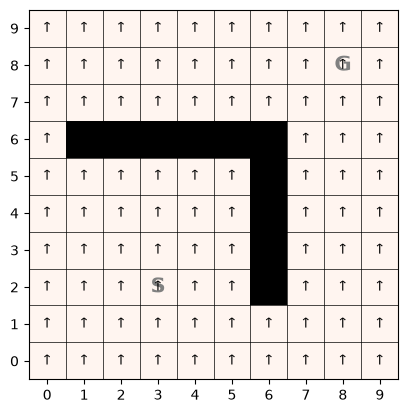

In [31]:
pol = np.zeros(len(pol_star))
env.image(policy = pol)

In [32]:
V = policy_evaluation(env, discount=1, policy=pol, max_backups=100)
env.print(V)

-101.00  -101.00  -101.00  -101.00  -101.00  -101.00  -101.00  -101.00  -101.00  -101.00  
-101.00  -101.00  -101.00  -101.00  -101.00  -101.00  -101.00  -101.00    +0.00  -101.00  
-101.00  -101.00  -101.00  -101.00  -101.00  -101.00  -101.00  -101.00    -1.00  -101.00  
-101.00                                                        -101.00    -2.00  -101.00  
-101.00  -101.00  -101.00  -101.00  -101.00  -101.00           -101.00    -3.00  -101.00  
-101.00  -101.00  -101.00  -101.00  -101.00  -101.00           -101.00    -4.00  -101.00  
-101.00  -101.00  -101.00  -101.00  -101.00  -101.00           -101.00    -5.00  -101.00  
-101.00  -101.00  -101.00  -101.00  -101.00  -101.00           -101.00    -6.00  -101.00  
-101.00  -101.00  -101.00  -101.00  -101.00  -101.00  -101.00  -101.00    -7.00  -101.00  
-101.00  -101.00  -101.00  -101.00  -101.00  -101.00  -101.00  -101.00    -8.00  -101.00  


No convergence, and the value function estimate is just an artifact of using `max_backups`.

Using $\gamma < 1$ leads again to convergence.

In [33]:
V = policy_evaluation(env, discount=.9, policy=pol, max_backups=100)
env.print(V)

-9.99  -9.99  -9.99  -9.99  -9.99  -9.99  -9.99  -9.99  -9.99  -9.99  
-9.99  -9.99  -9.99  -9.99  -9.99  -9.99  -9.99  -9.99  +0.00  -9.99  
-9.99  -9.99  -9.99  -9.99  -9.99  -9.99  -9.99  -9.99  -1.00  -9.99  
-9.99                                            -9.99  -1.90  -9.99  
-9.99  -9.99  -9.99  -9.99  -9.99  -9.99         -9.99  -2.71  -9.99  
-9.99  -9.99  -9.99  -9.99  -9.99  -9.99         -9.99  -3.44  -9.99  
-9.99  -9.99  -9.99  -9.99  -9.99  -9.99         -9.99  -4.10  -9.99  
-9.99  -9.99  -9.99  -9.99  -9.99  -9.99         -9.99  -4.69  -9.99  
-9.99  -9.99  -9.99  -9.99  -9.99  -9.99  -9.99  -9.99  -5.22  -9.99  
-9.99  -9.99  -9.99  -9.99  -9.99  -9.99  -9.99  -9.99  -5.70  -9.99  


&copy; 2026 [Michael Hahsler](https://michael.hahsler.net). 
This work is openly licensed under [Creative Commons Attribution-ShareAlike 4.0 International (CC BY-SA 4.0) License](https://creativecommons.org/licenses/by-sa/4.0/)

![CC BY-SA 4.0](https://licensebuttons.net/l/by-sa/3.0/88x31.png)